# 情感分析-初级

[参考网址在这里](https://www.jianshu.com/p/d50a14541d01)

首先，需要安装情感分析的运行环境，也就是一些必要的程序包
+ 在anaconda prompt里面运行

In [1]:
!pip install snownlp
!pip install -U textblob
!python -m textblob.download_corpora

[nltk_data] Downloading package brown to
[nltk_data]     /Users/wuzhixiang/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/wuzhixiang/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/wuzhixiang/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/wuzhixiang/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package conll2000 to
[nltk_data]     /Users/wuzhixiang/nltk_data...
[nltk_data]   Unzipping corpora/conll2000.zip.
[nltk_data] Downloading package movie_reviews to
[nltk_data]     /Users/wuzhixiang/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.
Finished.


## 英文

In [2]:
# 英文调出TextBlob NLP处理包

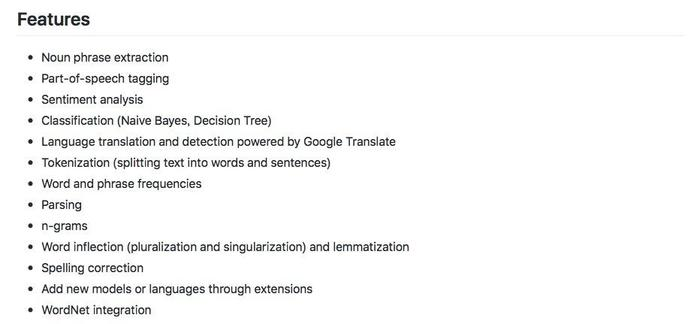

In [1]:
text = "I am happy today. I feel sad today."

In [2]:
from textblob import TextBlob
blob = TextBlob(text)

In [3]:
blob

TextBlob("I am happy today. I feel sad today.")

In [4]:
# 原封不动的打印出来了？
# 实际上已经把文本分成了句子了，看一看
blob.sentences

[Sentence("I am happy today."), Sentence("I feel sad today.")]

In [5]:
blob.sentences[0].sentiment

Sentiment(polarity=0.8, subjectivity=1.0)

In [6]:
# 上面的结果什么意思呢？
# 情感极性0.8，主观性1.0。说明一下，情感极性的变化范围是[-1, 1]，-1代表完全负面，1代表完全正面。
# 我表达的是我很高兴，那么这个结果是对的

In [7]:
blob.sentences[1].sentiment

Sentiment(polarity=-0.5, subjectivity=1.0)

In [8]:
# 整段文本的情感呢？
blob.sentiment

Sentiment(polarity=0.15000000000000002, subjectivity=1.0)

In [9]:
# 你可能会觉得没有道理。怎么一句“高兴”，一句“沮丧”，合并起来最后会得到正向结果呢？
# 首先不同极性的词，在数值上是有区别的。我们应该可以找到比“沮丧”更为负面的词汇。而且这也符合逻辑，谁会这么“天上一脚，地下一脚”矛盾地描述自己此时的心情呢？

##  中文

In [10]:
# 中文分析，用的是SnowNLP包

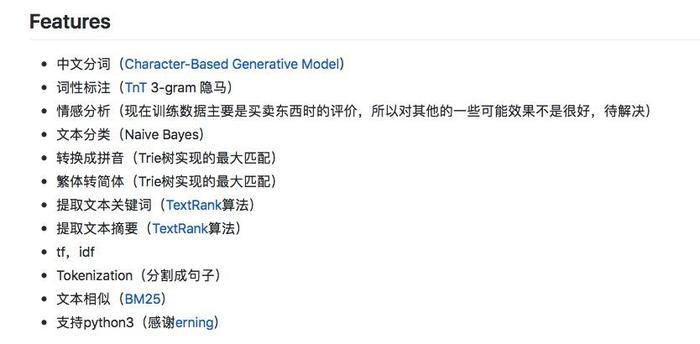

In [11]:
text_cn = u"我今天很快乐。我今天很愤怒。"

In [12]:
#注意在引号前面我们加了一个字母u，它很重要。因为它提示Python，“这一段我们输入的文本编码格式是Unicode，别搞错了哦”。至于文本编码格式的细节，有机会我们再详细聊。

In [13]:
from snownlp import SnowNLP

In [14]:
senti_cn = SnowNLP(text_cn)

In [15]:
# 看看snownlp包的分句能力
for sentence in senti_cn.sentences:
    print(sentence)

我今天很快乐
我今天很愤怒


In [16]:
senti_cn_1 = SnowNLP(senti_cn.sentences[0])

In [17]:
# 一个细节上的问题，英文是x.sentiment,中文是x.sentiments，多了一个s
# 另外，在句法上和英文的也略有不同，比如直接用语句：senti_cn.sentences[0].sentiments是会报错的
senti_cn_1.sentiments

0.971889316039116

In [18]:
senti_cn_2 = SnowNLP(senti_cn.sentences[1])

In [19]:
senti_cn_2.sentiments

0.07763913772213482

这里你肯定发现了问题——“愤怒”这个词表达了如此强烈的负面情感，为何得分依然是正的？

这是因为SnowNLP和textblob的计分方法不同。SnowNLP的情感分析取值，表达的是“这句话代表正面情感的概率”。也就是说，对“我今天很愤怒”一句，SnowNLP认为，它表达正面情感的概率很低很低。

这样解释就是ok了

In [20]:
senti_cn.sentiments

0.7237619924203508

In [21]:
# 整个句子，貌似就有问题了

## 作业

注：设计课程的时候，可以把作业单独拿出来，放在另外一个文档中

从淘宝或者其他平台上找一些评论的句子来试一试，它的情感值是多少。

In [22]:
# 例如
text_taobao_1 = "显示效果: 挺好的 运行速度: 目前来说很流畅 拍照效果: 拍照效果挺好的 电池续航: 一天一冲 总结: 目前没啥毛病，用了一天的体验"

In [23]:
taobao_1 = SnowNLP(text_taobao_1)

In [24]:
taobao_1.sentiments

0.999947261146611

In [25]:
text_taobao_2 = "总结: 这是我买过最不满意的一款手机！两千多元的手机这样，真的很不值！"

In [26]:
taobao_2 = SnowNLP(text_taobao_2)

In [27]:
for sentence in taobao_2.sentences:
    print(sentence)

总结: 这是我买过最不满意的一款手机
两千多元的手机这样
真的很不值


In [28]:
taobao_2.sentiments

0.889005139666256

In [29]:
# 以上的结果看上去是有问题的。分析的不准确。

In [30]:
text_taobao_3 = "显示效果: 像素不行 运行速度: 微信有时发给不了语音，得重新开机后才能发，才买半个月的手机就这样，客服态度也很差！ 拍照效果: 拍照不清晰！ 电池续航: 手机不蓄电，充满电后用半天就没电了，一天得充两次电！！ 总结: 这是我买过最不满意的一款手机！两千多元的手机这样，真的很不值！"

In [31]:
taobao_3 = SnowNLP(text_taobao_3)

In [32]:
taobao_3.sentiments

5.7076094222563434e-05

In [33]:
# 这一长句的结果还是可以的，非常小的概率值了

In [34]:
# 你的例句呢？

In [37]:
# 例句1

In [41]:
# 例句1：一条典型的正面好评（某电商平台的手机评价）
text_my_1 = "手机收到，屏幕清晰，运行流畅，拍照也好看，非常满意。"

senti_my_1 = SnowNLP(text_my_1)

# 先看看它分了几个句子
for sentence in senti_my_1.sentences:
    print(sentence)

senti_my_1.sentiments

手机收到，屏幕清晰，运行流畅，拍照也好看，非常满意。


0.9971457382572139

In [38]:
# 例句2

In [42]:
# 例句2：一条"先夸后贬"的转折句
text_my_2 = "东西是好东西，就是太贵了，性价比一般。"

senti_my_2 = SnowNLP(text_my_2)

for sentence in senti_my_2.sentences:
    print(sentence)

senti_my_2.sentiments

东西是好东西，就是太贵了，性价比一般。


0.9481526554185977

In [39]:
# 查看原博客的地址，了解下有时候分析结果不准确的原因。

把这两句放回刚才那三条淘宝评论里对照，问题就清楚了。

例句 1 是纯正面评价，SnowNLP 给出 **0.9971**，判断正确。

例句 2 表面上先夸了一句"东西是好东西"，但后面跟着"就是太贵了，性价比一般"，整体是抱怨，SnowNLP 却给了 **0.9482**，判成相当正面。原因有这么几条：

1. **它算的是"正面概率"，不是情感极性。** SnowNLP 用电商评论语料训练，输出的是"这句话属于正面情感的可能性"，0 到 1 之间。数值高只说明像好评，不代表评价真的让人满意。
2. **按词加权，看不见句子的转折结构。** "好"字在前面出现，权重被加上去；"就是"这种转折连词不在情感词典里，后面"太贵""一般"的分量压不过来。整句被前半句带偏。
3. **否定和程度副词处理粗糙。** 前面老师给的 `taobao_2`（"最不满意的一款手机……真的很不值"）得分 0.889 也是同一个毛病，短句里"不满意"被拆开计分，否定词没起作用。
4. **反讽、隐喻一律识别不了。** "这价格买到这种质量，我真是服了"，字面全是中性甚至正面词，实际是骂人。
5. **缺少上下文与领域知识。** 同一句话放在数码区和母婴区，含义可能不同；模型没有这块知识。

所以结论跟程序 2 里经理得到的教训一致：情感分析适合用来**快速筛出可疑样本**，不适合直接下判断。真要下判断，人得回头看原文。